In [1]:
import pyuvdata
import numpy as np
import matplotlib.pyplot as plt
from calico import caldata
import importlib
importlib.reload(caldata)

<module 'calico.caldata' from '/opt/devel/rbyrne/envs/py311/lib/python3.11/site-packages/calico/caldata.py'>

In [2]:
data = pyuvdata.UVData()
data.read("/fast/rbyrne/20260419_055641-055832_44MHz_wsclean_selfcal_deep_flagging_tmp_dir/20260419_055641-055832_44MHz_wsclean_selfcal_calibrated_1freq.ms", ignore_single_chan=False)

model_list = []
model1 = pyuvdata.UVData()
model1.read("/fast/rbyrne/20260419_055641-055832_44MHz_wsclean_selfcal_deep_flagging_tmp_dir/20260419_055641-055832_44MHz_VirA_sim_1freq.ms", ignore_single_chan=False)
model_list.append(model1)
model2 = pyuvdata.UVData()
model2.read("/fast/rbyrne/20260419_055641-055832_44MHz_wsclean_selfcal_deep_flagging_tmp_dir/20260419_055641-055832_44MHz_CasA_sim_1freq.ms", ignore_single_chan=False)
model_list.append(model2)

In [3]:
data.select(polarizations=[-5], inplace=True)
for model in model_list:
    model.select(polarizations=[-5], inplace=True)

In [4]:
caldata_obj = caldata.CalData()
caldata_obj.load_data(
    data=data,
    model_list=model_list,
    gain_init_to_vis_ratio=False,
    gains_multiply_model=True,
    gain_init_stddev=0,
    check_vis_ordering=True,
    min_cal_baseline_lambda=None,
    max_cal_baseline_lambda=None,
    lambda_val=0,
    verbose=True,
    parallel=False,
    ddcal_max_source_offset_deg=None,
)

In [5]:
caldata_obj.direction_dependent_calibration()

An NVIDIA GPU may be present on this machine, but a CUDA-enabled jaxlib is not installed. Falling back to cpu.


         Current function value: 6652766.000000
         Iterations: 9
         Function evaluations: 78
         Gradient evaluations: 66
         Hessian evaluations: 10
Freq. 0 Pol. 0, optimization time: 1.4881315628687541 minutes


In [12]:
caldata_obj_regularized = caldata_obj.copy()
#caldata_obj_regularized.gains = np.abs(caldata_obj.gains) + 1j*0
caldata_obj_regularized.initialize_gains()
caldata_obj_regularized.ddcal_max_source_offset_deg = 2
caldata_obj_regularized.ddcal_source_offset_taper_deg = 2
caldata_obj_regularized.direction_dependent_calibration()

divide by zero encountered in divide


         Current function value: 6654344.000000
         Iterations: 5
         Function evaluations: 19
         Gradient evaluations: 13
         Hessian evaluations: 6
Freq. 0 Pol. 0, optimization time: 0.814866816997528 minutes


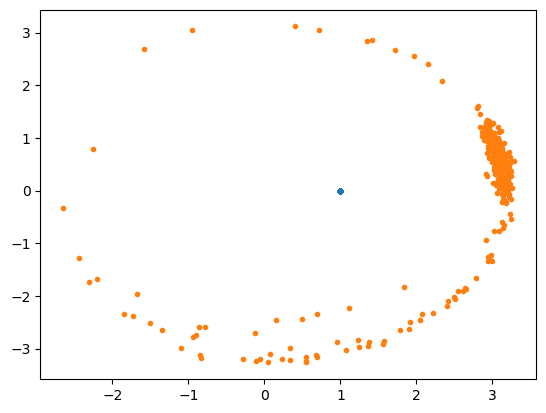

In [13]:
plt.plot(np.real(caldata_obj.gains[:, 0, 0,0]), np.imag(caldata_obj.gains[:, 0, 0,0]), ".")
plt.plot(np.real(caldata_obj_regularized.gains[:, 0, 0,0]), np.imag(caldata_obj_regularized.gains[:, 0, 0,0]), ".")

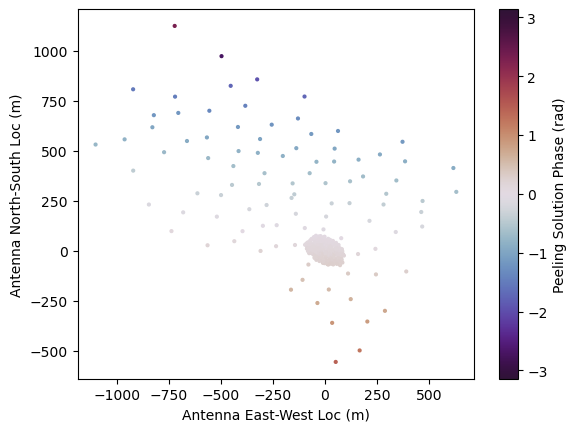

In [9]:
for direction_ind in range(1):
    for pol_ind in range(1):
        sc = plt.scatter(
            caldata_obj_regularized.antenna_positions[:, 0],
            caldata_obj_regularized.antenna_positions[:, 1],
            c=np.angle(caldata_obj_regularized.gains[:, 0, pol_ind, direction_ind]),
            cmap="twilight_shifted",
            s=4,
            vmin=-np.pi,
            vmax=np.pi,
        )
        plt.xlabel("Antenna East-West Loc (m)")
        plt.ylabel("Antenna North-South Loc (m)")
        plt.colorbar(sc, label="Peeling Solution Phase (rad)")
        plt.show()

In [8]:
caldata_obj.antenna_distances

array([ 397.52248824,  951.8260996 ,  475.16770398,  440.73640094,
        868.42304339,  574.463046  ,  786.2316475 ,  877.59724412,
        707.03880042,  658.50770478,  520.77737403,  372.57497239,
        566.45839999,  668.43865528,  686.24497811,  665.0645005 ,
        555.85574464,  604.77159511,  476.59479421,  692.45478407,
        891.43035251,  403.69711439,  794.32832635,  964.9120908 ,
        381.07902837,  795.2878516 ,  737.95811994,  807.96662557,
        724.1391956 , 1330.14632923,  711.27620674, 1587.84280435,
        737.5268486 ,  265.14459254,  648.58575669, 1099.23298875,
        326.16768548,  490.17040541,  943.29371497,  678.86811256,
        815.39482174,  779.68343565,  856.90159194,  442.40466006,
        920.61293578, 1051.99679955,  751.18710459,  564.67361516,
        651.09183826, 1142.42282886,  419.11167622,  488.7764641 ,
        429.39132891,  561.85359506, 1047.97370433,  365.83167043,
        755.55775044,  920.68752283,  499.04218395,  373.51264

10.388658817524252


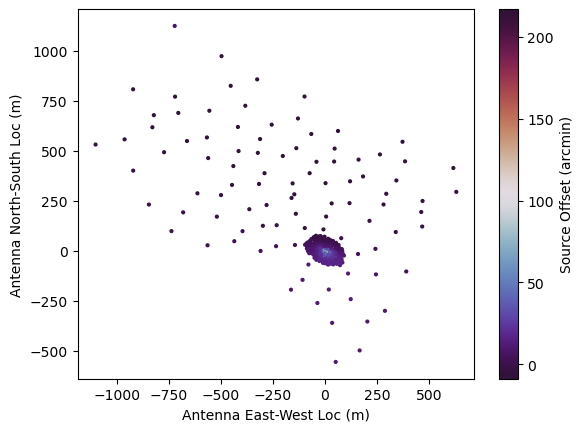

9.032387351153096


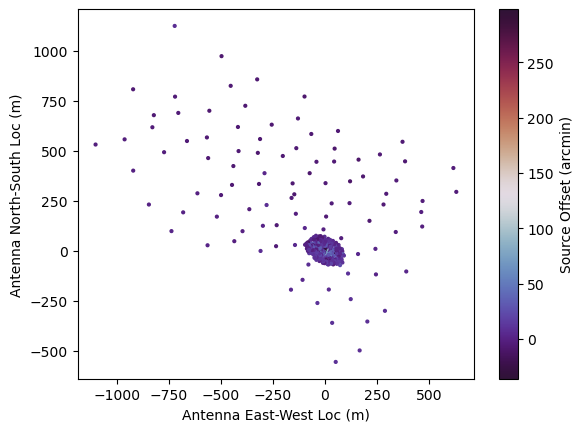

9.952929019941763


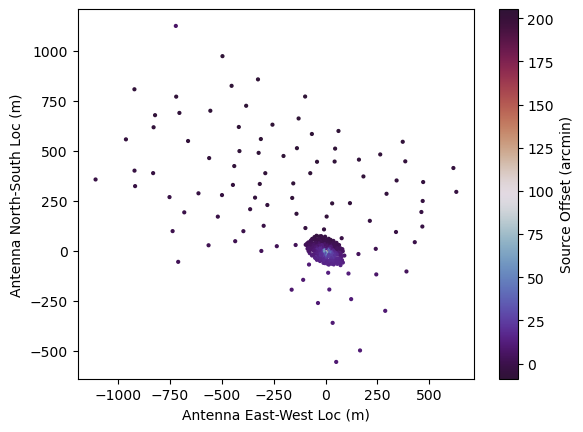

9.287879993780152


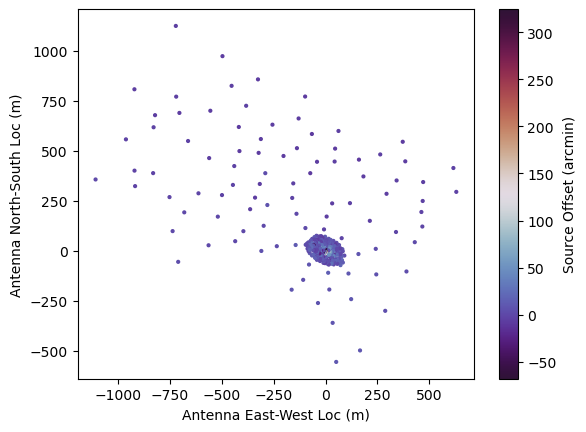

In [38]:
for pol_ind in range(2):
    for direction_ind in range(2):
        angle_offsets = np.arcsin(
            3e8 
            * np.angle(caldata_obj.gains[:, 0, pol_ind, direction_ind])
            / (2 * np.pi * caldata_obj.freq_array[0] * caldata_obj.antenna_distances)
        )
        print(np.rad2deg(np.nanmean(angle_offsets))*60)

        sc = plt.scatter(
            caldata_obj.antenna_positions[:, 0],
            caldata_obj.antenna_positions[:, 1],
            c=np.rad2deg(angle_offsets)*60,
            cmap="twilight_shifted",
            s=4,
            #vmin=-np.pi,
            #vmax=np.pi,
        )
        plt.xlabel("Antenna East-West Loc (m)")
        plt.ylabel("Antenna North-South Loc (m)")
        plt.colorbar(sc, label="Source Offset (arcmin)")
        plt.show()

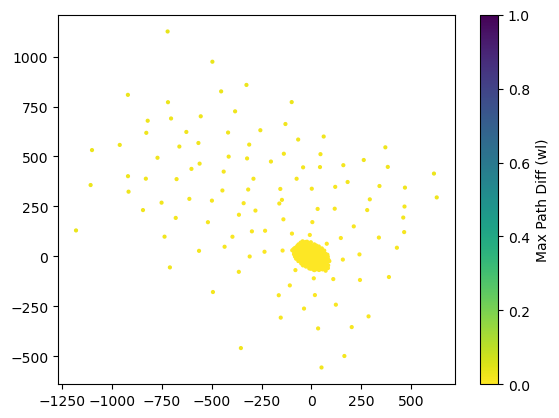

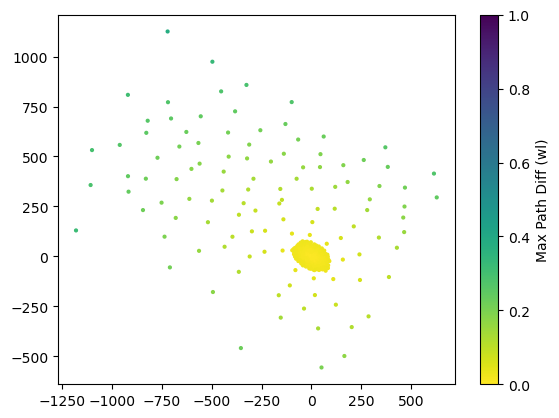

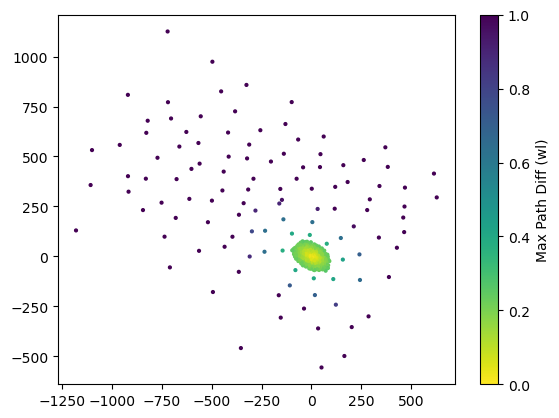

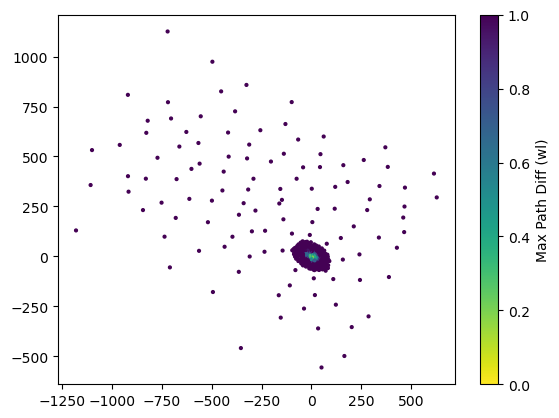

In [6]:
for max_source_offset_deg in [.01, .1, 1, 10]:
    max_path_length_difference_wl = (
        caldata_obj.antenna_distances[:, np.newaxis] * caldata_obj.freq_array[np.newaxis, :] / 3e8
    ) * np.sin(np.deg2rad(max_source_offset_deg))
    sc = plt.scatter(
        caldata_obj.antenna_positions[:, 0],
        caldata_obj.antenna_positions[:, 1],
        c=max_path_length_difference_wl,
        cmap="viridis_r",
        s=4,
        vmin=0,
        vmax=1,
    )
    plt.colorbar(sc, label="Max Path Diff (wl)")
    plt.show()

In [4]:
caldata_regularized = caldata_obj.copy()
caldata_regularized.initialize_gains()
caldata_regularized.ddcal_max_source_offset_deg = 10
caldata_regularized.direction_dependent_calibration()

divide by zero encountered in divide
An NVIDIA GPU may be present on this machine, but a CUDA-enabled jaxlib is not installed. Falling back to cpu.


TypeError: unsupported operand type(s) for +: 'int' and 'NoneType'

In [9]:
caldata_regularized_strict = caldata_obj.copy()
caldata_regularized_strict.initialize_gains()
caldata_regularized_strict.ddcal_max_source_offset_deg = 1
caldata_regularized_strict.direction_dependent_calibration()

divide by zero encountered in divide


         Current function value: 1580379.375000
         Iterations: 24
         Function evaluations: 107
         Gradient evaluations: 95
         Hessian evaluations: 25
Freq. 0 Pol. 0, optimization time: 2.93695908387502 minutes


         Current function value: 1277635.375000
         Iterations: 27
         Function evaluations: 87
         Gradient evaluations: 75
         Hessian evaluations: 28
Freq. 0 Pol. 1, optimization time: 3.504642128944397 minutes


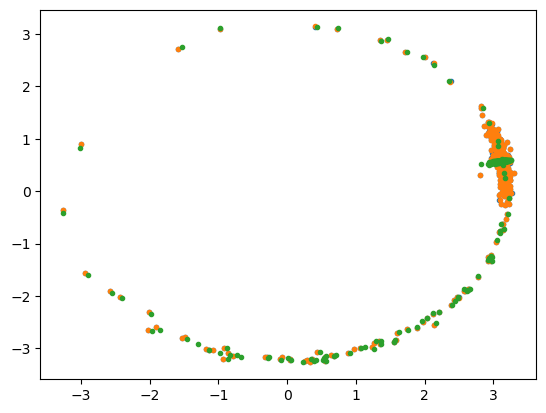

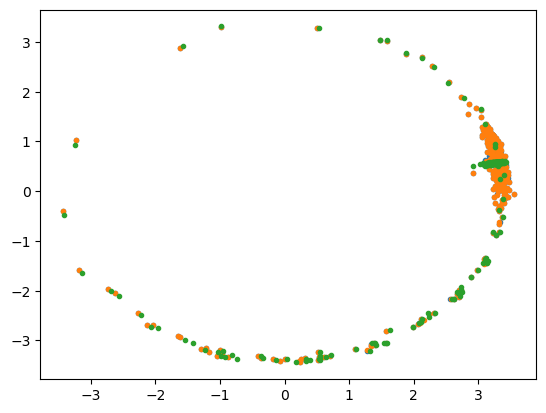

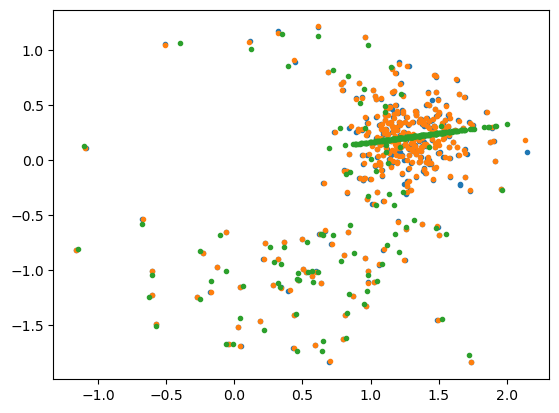

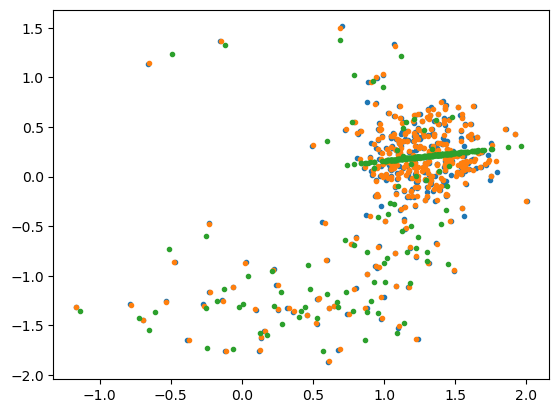

In [10]:
for direction_ind in range(2):
    for pol_ind in range(2):
        plt.plot(np.real(caldata_obj.gains[:, :, pol_ind, direction_ind].flatten()), np.imag(caldata_obj.gains[:, :, pol_ind, direction_ind].flatten()), ".")
        plt.plot(np.real(caldata_regularized.gains[:, :, pol_ind, direction_ind].flatten()), np.imag(caldata_regularized.gains[:, :, pol_ind, direction_ind].flatten()), ".")
        plt.plot(np.real(caldata_regularized_strict.gains[:, :, pol_ind, direction_ind].flatten()), np.imag(caldata_regularized_strict.gains[:, :, pol_ind, direction_ind].flatten()), ".")
        plt.show()

In [3]:
cal = pyuvdata.UVCal()
cal.read("/fast/rbyrne/20260419_055641-055832_44MHz_wsclean_selfcal_deep_flagging_tmp_dir/20260419_055641-055832_peeled_regularized_solution.calfits")

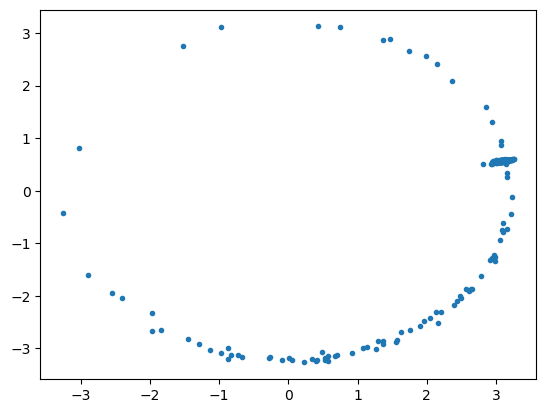

In [5]:
plt.plot(np.real(cal.gain_array[:, 0,0,0]), np.imag(cal.gain_array[:, 0,0,0]), ".")

In [42]:
data = pyuvdata.UVData()
data.read(
    "/fast/rbyrne/20260419_055641-055832_44MHz_wsclean_selfcal_deep_flagging_tmp_dir/20260419_055641-055832_44MHz_wsclean_selfcal_calibrated_1freq.ms",
    ignore_single_chan=False,
)
model = pyuvdata.UVData()
model.read(
    "/fast/rbyrne/20260419_055641-055832_44MHz_wsclean_selfcal_deep_flagging_tmp_dir/20260419_055641-055832_44MHz_VirA_sim_1freq.ms",
    ignore_single_chan=False,
)
model2 = pyuvdata.UVData()
model2.read(
    "/fast/rbyrne/20260419_055641-055832_44MHz_wsclean_selfcal_deep_flagging_tmp_dir/20260419_055641-055832_44MHz_CasA_sim_1freq.ms",
    ignore_single_chan=False,
)
caldata_obj = caldata.CalData()
caldata_obj.load_data(
    data=data,
    model_list=[model, model2],
    gain_init_to_vis_ratio=False,
    gains_multiply_model=True,
    gain_init_stddev=0,
    check_vis_ordering=True,
    min_cal_baseline_lambda=10,
    max_cal_baseline_lambda=125,
    xtol=1e-5,
    maxiter=200,
    get_crosspol_phase=False,
    lambda_val=0,
    verbose=True,
    parallel=False,
)

KeyboardInterrupt: 

In [ ]:
np.sum(caldata_obj.visibility_weights)

np.float64(0.9999999999999994)

In [ ]:
max_freq = np.max(caldata_obj.freq_array)
ant_dist_wls = caldata_obj.antenna_distances * max_freq / 3e8

In [ ]:
print(ant_dist_wls)

[ 54.75186446 131.09762374  65.44615334  60.70383538 119.61029167
  79.1223736  108.2898449  120.87387954  97.3823965   90.69807536
  71.72809851  51.31577456  78.01987172  92.06589246  94.51840622
  91.60116085  76.55953887  83.29685334  65.6427104   95.37369986
 122.77915156  55.60231268 109.40502272 132.89999326  52.48706155
 109.53718077 101.64099932 111.28346314  99.73768091 183.20470836
  97.96602611 218.69795188 101.58159914  36.51909319  89.33149819
 151.40037957  44.92397143  67.51251663 129.92243496  93.50237026
 112.30656901 107.38794169 118.02341051  60.93360929 126.79854893
 144.89440945 103.46306372  77.7740484   89.67666769 157.34903491
  57.72540263  67.32052526  59.14124744  77.38563928 144.3402975
  50.38700105 104.06504478 126.80882201  68.73445106  51.44492244
 122.41096472  78.7678417  114.63424769 188.54280566  12.61119431
  13.87769053  10.81457393  13.2967777   10.97576085  12.95726415
  10.20233359  13.51636988  11.46164216   8.92691716  11.1873437
  10.7182657

In [ ]:
max_source_offset_deg = 10
max_source_offset_rad = np.deg2rad(max_source_offset_deg)
print(np.max(np.sin(max_source_offset_rad) * ant_dist_wls))

37.976500802632366


In [ ]:
ddcal_max_source_offset_deg = 10
max_path_length_difference_wl = (
    caldata_obj.antenna_distances[:, np.newaxis] * caldata_obj.freq_array[np.newaxis, :] / 3e8
) * np.sin(np.deg2rad(ddcal_max_source_offset_deg))

In [ ]:
np.shape(max_path_length_difference_wl)

(352, 1)

In [ ]:
cal = pyuvdata.UVCal()
cal.read("/fast/rbyrne/20260419_055641-055832_44MHz_wsclean_selfcal_deep_flagging_tmp_dir/20260419_055641-055832_peeled_solution.calfits")

cal2 = pyuvdata.UVCal()
cal2.read("/fast/rbyrne/20260419_055641-055832_44MHz_wsclean_selfcal_deep_flagging_tmp_dir/20260419_055641-055832_peeled_regularized_solution.calfits")

In [ ]:
np.shape(cal.gain_array)

(352, 1, 1, 2)

In [ ]:
(-np.pi/2)%(2*np.pi) / (2 * np.pi)

0.75

In [ ]:
cal.telescope.antenna_locations

AttributeError: 'Telescope' object has no attribute 'antenna_locations'

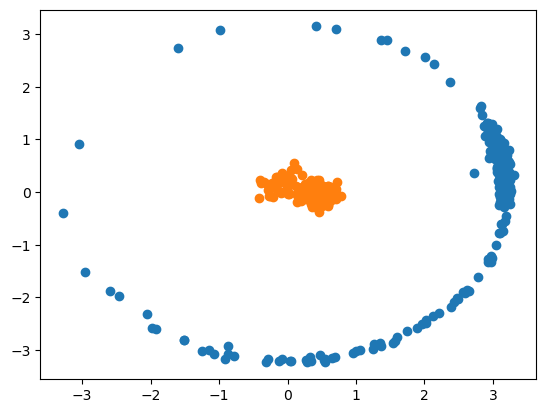

In [ ]:
plt.scatter(np.real(cal.gain_array[:, :, :, 0]), np.imag(cal.gain_array[:, :, :, 0]))
plt.scatter(np.real(cal2.gain_array[:, :, :, 0]), np.imag(cal2.gain_array[:, :, :, 0]))

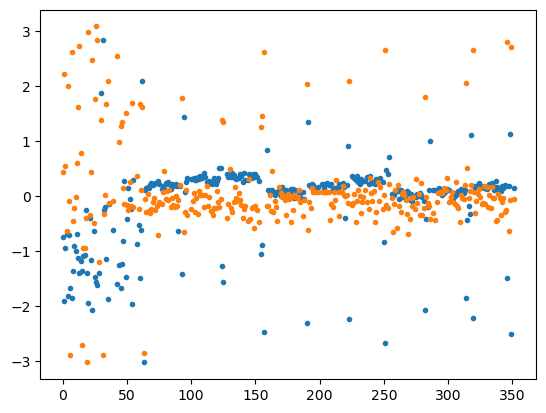

In [ ]:
plt.plot(np.angle(cal.gain_array[:, 0, 0, 0]), ".")
plt.plot(np.angle(cal2.gain_array[:, 0, 0, 0]), ".")